# NLP - Embeddings, RNNs and LSTMs 


## Basic Assignment

The notebook will help you practice Many-to-One RNN architecture, as well as Many-to-Many architectures.

The advanced part is included in a different notebook also available in Canvas.


In [1]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from tqdm import tqdm
import numpy as np
import re
from matplotlib import pyplot as plt
from nltk.corpus import treebank
from gensim.models import KeyedVectors
from keras.optimizers import Adam
# from keras.preprocessing.text import Tokenizer ## this is DEPRECATED
from keras.layers import TextVectorization
from keras.preprocessing.sequence import pad_sequences
# from keras.utils.np_utils import to_categorical
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Embedding
from keras.layers import Dense, Input
from keras.layers import TimeDistributed
from keras.layers import LSTM, GRU, SimpleRNN
from keras.models import Model
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
import pandas as pd
import nltk
import tensorflow as tf
import string
from tensorflow.keras.preprocessing.text import Tokenizer

In [2]:
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  0


### Loading the dataset
We will work on a binary classification problem. The dataset is of two classes SPAM and NOT SPAM. 

In [3]:
dataset=pd.read_csv("spam.csv", encoding='ISO-8859-1')


In [4]:
X=dataset.v2
X

0       Go until jurong point, crazy.. Available only ...
1                           Ok lar... Joking wif u oni...
2       Free entry in 2 a wkly comp to win FA Cup fina...
3       U dun say so early hor... U c already then say...
4       Nah I don't think he goes to usf, he lives aro...
                              ...                        
5567    This is the 2nd time we have tried 2 contact u...
5568                Will Ì_ b going to esplanade fr home?
5569    Pity, * was in mood for that. So...any other s...
5570    The guy did some bitching but I acted like i'd...
5571                           Rofl. Its true to its name
Name: v2, Length: 5572, dtype: object

In [5]:
y=dataset.v1
y

0        ham
1        ham
2       spam
3        ham
4        ham
        ... 
5567    spam
5568     ham
5569     ham
5570     ham
5571     ham
Name: v1, Length: 5572, dtype: object

### Exercise 1
Reuse your to_lower(X) function from the NLP basic lab, and the clean_text(X) function to lower case all documents in the dataset and then remove all numerical and special characters from the dataset.

In [6]:
#Add your code here
def to_lower(X):
    X = X.apply(lambda x : x.lower())
    return X

def clean_text(X):
    special_char = set(string.punctuation)
    numbers = set("0123456789")

    for idx in tqdm(range(len(X))):
        text = X.iloc[idx]
        for char in special_char | numbers:
            text = text.replace(char, '')
        X.iloc[idx] = text

    return X

X = to_lower(X)
X = clean_text(X)

X.head()

100%|██████████| 5572/5572 [00:00<00:00, 43090.60it/s]


0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in  a wkly comp to win fa cup final...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: v2, dtype: object

### Exercise 2 
Create the ground truth vector **y** for the binary classification.
Check that the **y** vector is of shape(ne,1).

In [7]:
#Add your code here
print(len(X))
le = LabelEncoder()
le.fit(y)
y = le.transform(y)

5572


In [8]:
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5572,))

### Exercise 3
Use Keras' Tokenizer class to vectorize the corpus. 
What we expect here is that the tokens will be encoded as integers.


Notice that tokenizing here is different from the tokenization process discussed in the basic lecture.

In [9]:
#Add your code here
lengths = sorted([len(s.split()) for s in X], reverse=True)
vocab_size = 5000

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<UNK>")
tokenizer.fit_on_texts(X)
X_encoded = tokenizer.texts_to_sequences(X) 
print(len(tokenizer.word_index))

8620


In [10]:
i=25
print(X[i])
print(X_encoded[i])

just forced myself to eat a slice im really not hungry tho this sucks mark is getting worried he knows im sick when i turn down pizza lol
[37, 4006, 939, 2, 314, 5, 2732, 23, 149, 25, 737, 636, 40, 1222, 1112, 10, 246, 1020, 72, 940, 23, 1021, 43, 3, 1776, 226, 1113, 178]


### Exercise 4
Whether we work with an RNN cell, an LSTM or a GRU cell, we want first to know how many times should we unroll the network. This will be referred to as 'time_steps'.


In this exercise, the goal is to check the lengths of our documents, and then choose a fixed length for all our documents. 

Documents which are shorter than the length you fixed will be padded with 0s.

Documents which are longer will be truncated. 


a. Check the length of the largest document in the corpus

In [11]:
#Add your code here
print(lengths[0])

171


b. Check the average count of words in all documents

In [12]:
print("Average word count in our documents is", int(sum(lengths)/len(lengths)))

Average word count in our documents is 14


Quite a distance between the average length and longest document. It's probably worth it to check the lengths in a box plot.

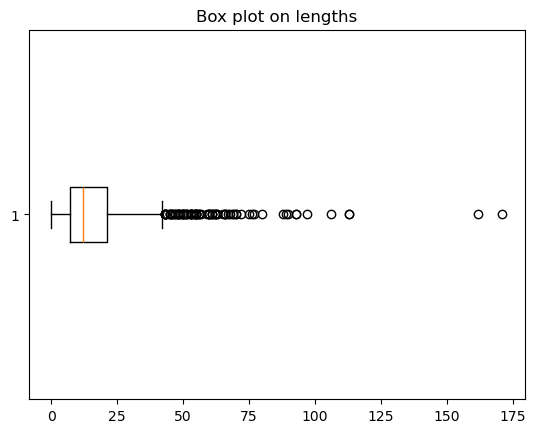

In [13]:
#Visualize the length of the docs here
plt.boxplot(lengths, orientation="horizontal")
plt.title("Box plot on lengths")
plt.show()

### Exercise 5

Hopefully, you have chosen a value for the max doc length (which will serve as your time_steps value when you build your RNN).

We can now proceed to use the pad_sequences() method of Keras to pad our sequences, check [here](https://www.tensorflow.org/api_docs/python/tf/keras/utils/pad_sequences).

Sentences longer than **n** will be truncated (you can choose to keep the first **n** words or the last).
Sentences shorter than **n** will be padded with 0.

In [14]:
#Add your code here
X_padded = pad_sequences(X_encoded, maxlen=50, padding="post", truncating="post")

In [15]:
i=5214
print(X[i])
print(X_encoded[i])
print(X_padded[i])
print(y[i])

natalja f is inviting you to be her friend reply yes or no see her wwwsmsacunat stop send stop frnd to 
[3906, 793, 10, 1382, 4, 2, 32, 107, 263, 90, 143, 27, 38, 82, 107, 3907, 86, 70, 86, 685, 2]
[3906  793   10 1382    4    2   32  107  263   90  143   27   38   82
  107 3907   86   70   86  685    2    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]
1


### Exercise 6

We can now proceed to pass our padded sequences and our **y** vector to an RNN model for training.
Let's first define a simple RNN model.

In [16]:
# split entire data into training and testing sets
TEST_SIZE = 0.25
X_train, X_test, y_train, y_test = train_test_split(X_padded, y, test_size=TEST_SIZE, random_state=100)

**Do check the size of the vocab, needed for the rest of the exercises.**

This dataset was chosen particularly for its small vocab size.

In [17]:
print(len(tokenizer.word_index))  # full vocab; we cap it at vocab_size = 5000


8620


### Exercise7

Let's first try a classification task using basic RNN cells.

You're free to define the number of units and layers as you see fit.

a. Define the architecture of your model and print its summary.

In [18]:
#Add your code here
#Print the summary of your model also
model = Sequential()
model.add(Input(shape=(50,)))
model.add(Embedding(input_dim=vocab_size, output_dim=32, mask_zero=True))
model.add(SimpleRNN(50))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         4,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,201 (641.41 KB)

 Trainable params: 164,201 (641.41 KB)

 Non-trainable params: 0 (0.00 B)

b. Compile your model. 

Use the loss function and the optimizer you want, you don't have to use binary_cross entropy and stochastic gradient descent.

In [19]:
#Add your code here
model.compile(optimizer=Adam(0.00005), 
              loss="binary_crossentropy",
              metrics=["acc"])

c. Train your model

In [20]:
#Add your code here
#You should be able to see some good results from the first few epochs.
#Feel free to work with the dataset from the basic lab, a much more complex one, but with a larger vocab

m_history = model.fit(X_train, y_train, epochs=15, batch_size=32,  validation_split=0.1)

Epoch 1/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - acc: 0.7663 - loss: 0.6241 - val_acc: 0.8517 - val_loss: 0.5631
Epoch 2/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.8684 - loss: 0.4966 - val_acc: 0.8947 - val_loss: 0.4291
Epoch 3/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.9327 - loss: 0.3277 - val_acc: 0.9498 - val_loss: 0.2661
Epoch 4/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.9620 - loss: 0.2225 - val_acc: 0.9617 - val_loss: 0.2098
Epoch 5/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.9686 - loss: 0.1729 - val_acc: 0.9641 - val_loss: 0.1758
Epoch 6/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.9777 - loss: 0.1428 - val_acc: 0.9665 - val_loss: 0.1548
Epoch 7/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - acc: 0.9779 - loss: 0.1235 - val_acc: 0.9641 - val_loss: 0.1427
Epoch 8/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.9806 - loss: 0.1095 - val_acc: 0.9665 - val_loss: 0.1328
Epoch 9/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - ac

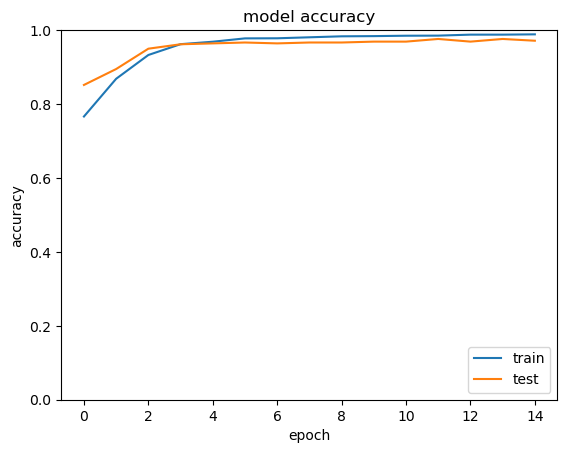

In [21]:
# visualise training history
plt.plot(m_history.history['acc'])
plt.plot(model.history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.ylim(0,1)
plt.legend(['train', 'test'], loc="lower right")
plt.show()

### Exercise 8
Try to perform the same classification task using an LSTM architecture.

a. Define the architecture of your model and print its summary.

In [22]:
#Add your code here

model_lstm = Sequential()
model_lstm.add(Input(shape=(50,)))
model_lstm.add(Embedding(input_dim=vocab_size, output_dim=32, mask_zero=True))
model_lstm.add(LSTM(50))
model_lstm.add(Dense(1, activation='sigmoid'))
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50)             │        16,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 176,651 (690.04 KB)

 Trainable params: 176,651 (690.04 KB)

 Non-trainable params: 0 (0.00 B)

b. compile your model.

In [23]:
#Add your code here

model_lstm.compile(optimizer=Adam(0.00005), loss='binary_crossentropy',  metrics=['acc'])

c. Train your model.

In [24]:

#Add your code here
m_history_lstm = model_lstm.fit(X_train, y_train, batch_size=32, epochs=10, validation_split=0.1)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - acc: 0.8431 - loss: 0.6795 - val_acc: 0.8541 - val_loss: 0.6610
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.8649 - loss: 0.6107 - val_acc: 0.8541 - val_loss: 0.5374
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.8649 - loss: 0.4893 - val_acc: 0.8541 - val_loss: 0.4626
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.8652 - loss: 0.4167 - val_acc: 0.8589 - val_loss: 0.3859
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.8788 - loss: 0.3436 - val_acc: 0.8995 - val_loss: 0.3097
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9160 - loss: 0.2817 - val_acc: 0.9330 - val_loss: 0.2539
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9386 - loss: 0.2345 - val_acc: 0.9593 - val_loss: 0.2159
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9540 - loss: 0.1999 - val_acc: 0.9617 - val_loss: 0.1868
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/s

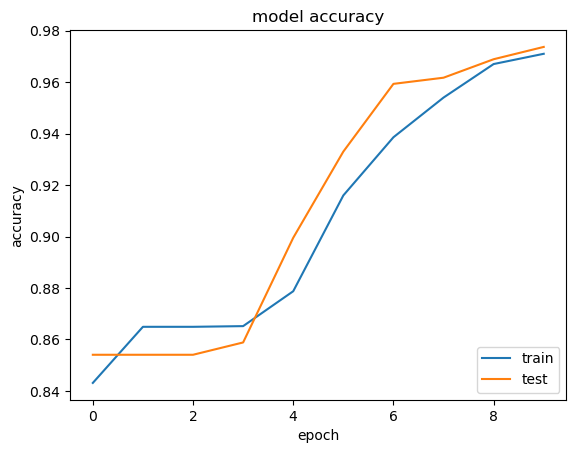

In [25]:
# visualise training history
plt.plot(m_history_lstm.history['acc'])
plt.plot(model_lstm.history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc="lower right")
plt.show()

### Exercise 9

Let's now see whether we get different results using a GRU cell.

a. Define the architecture of your model and print its summary.

In [26]:
#Add your code here
model_gru = Sequential()
model_gru.add(Input(shape=(50, )))
model_gru.add(Embedding(input_dim=vocab_size, output_dim=32, mask_zero=True))
model_gru.add(GRU(50))
model_gru.add(Dense(1, activation='sigmoid'))
model_gru.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 50)             │        12,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,651 (674.42 KB)

 Trainable params: 172,651 (674.42 KB)

 Non-trainable params: 0 (0.00 B)

b. Compile your model

In [27]:
#Add your code here

model_gru.compile(optimizer=Adam(0.00005), loss='binary_crossentropy', metrics=['acc'])

c. Train your model

In [28]:
#Add your code here
m_history_gru = model_gru.fit(X_train, y_train, batch_size=32, epochs=10, validation_split=0.1)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - acc: 0.8224 - loss: 0.6736 - val_acc: 0.8541 - val_loss: 0.6510
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.8649 - loss: 0.6142 - val_acc: 0.8541 - val_loss: 0.5689
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - acc: 0.8649 - loss: 0.4982 - val_acc: 0.8541 - val_loss: 0.4415
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - acc: 0.8649 - loss: 0.4053 - val_acc: 0.8541 - val_loss: 0.3881
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.8649 - loss: 0.3556 - val_acc: 0.8541 - val_loss: 0.3345
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.8663 - loss: 0.3069 - val_acc: 0.8636 - val_loss: 0.2836
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - acc: 0.8796 - loss: 0.2605 - val_acc: 0.8756 - val_loss: 0.2375
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - acc: 0.9075 - loss: 0.2186 - val_acc: 0.9306 - val_loss: 0.1945
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/st

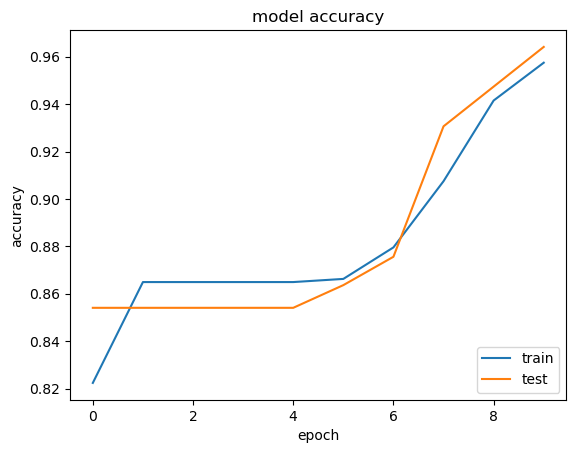

In [29]:
# visualise training history
plt.plot(m_history_gru.history['acc'])
plt.plot(model_gru.history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc="lower right")
plt.show()

### Exercise 10
It's now time to try training our model using pretrained word embeddings.

a. First, get the pretrained word embeddings of your choice, you can get;

1. You can get Google word2vec from [here](https://code.google.com/archive/p/word2vec/), these embeddings are vectors of size 300
2. You can get Stanford's GloVe embeddings from [here](https://nlp.stanford.edu/projects/glove/), you are offered a choice between embedding vectors of sizes 40, 50, 100, 200 and 300

a. Use the Gensim library to load your embeddings

Feel free to use other libraries also.

In [30]:
#Add your code here
word2vec = KeyedVectors.load_word2vec_format("GoogleNews-vectors-negative300.bin", binary=True)


b. If you work with embeddings of size 300 for example, then create a matrix **embeddings**. The shape of the matrix is (vocab_size, embedding_size=300). Each row corresponds to the embeddings of one word in your vocab.

In [31]:
#Add your code here
embd_dim = word2vec.vector_size
embd_weights = np.zeros(shape=(vocab_size, embd_dim))


c. Print the embedding_weights shape

In [32]:
#Add your code here
found = 0
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size and word in word2vec:
        embd_weights[idx] = word2vec[word]
        found += 1
print("Number of vocabs found in word2vec:", found)
print(embd_weights.shape)

Number of vocabs found in word2vec: 3985
(5000, 300)


### Exercise 11
Let's now retrain our models, Simple RNN, LSTM and GRU using these embeddings.

Let's start by doing it for RNN again.

Define the architecture of your model again, show its summary, compile it and train it.

In [33]:
#Add your code here
import keras
model = Sequential()
model.add(Input(shape=(50,)))
model.add(Embedding(input_dim=vocab_size, output_dim=embd_dim, embeddings_initializer=keras.initializers.Constant(embd_weights), mask_zero=True))
model.add(SimpleRNN(50))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 50, 300)        │     1,500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │        17,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,517,601 (5.79 MB)

 Trainable params: 1,517,601 (5.79 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
#Add your code here
model.compile(optimizer=Adam(0.00005), 
              loss="binary_crossentropy",
              metrics=["acc"])

In [35]:
#Add your code here

m_history = model.fit(X_train, y_train, epochs=15, batch_size=32,  validation_split=0.1)

Epoch 1/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - acc: 0.7490 - loss: 0.5637 - val_acc: 0.8469 - val_loss: 0.4615
Epoch 2/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.8694 - loss: 0.3884 - val_acc: 0.8589 - val_loss: 0.3449
Epoch 3/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.8976 - loss: 0.2852 - val_acc: 0.9306 - val_loss: 0.2251
Epoch 4/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - acc: 0.9474 - loss: 0.1919 - val_acc: 0.9689 - val_loss: 0.1413
Epoch 5/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - acc: 0.9686 - loss: 0.1343 - val_acc: 0.9737 - val_loss: 0.1079
Epoch 6/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.9750 - loss: 0.1059 - val_acc: 0.9785 - val_loss: 0.0916
Epoch 7/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.9777 - loss: 0.0894 - val_acc: 0.9833 - val_loss: 0.0790
Epoch 8/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.9806 - loss: 0.0774 - val_acc: 0.9809 - val_loss: 0.0799
Epoch 9/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/

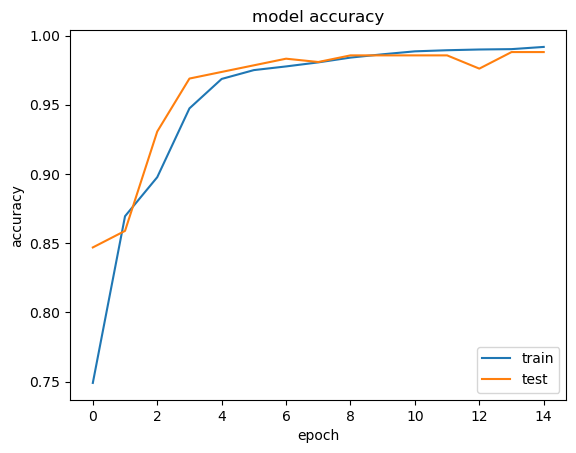

In [36]:
# visualise training history
plt.plot(m_history.history['acc'])
plt.plot(model.history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc="lower right")
plt.show()

### Exercise 12

Let's now retrain the model with LSTM architecture.

Define the architecture of your model again, show its summary, compile it and train it.

In [37]:
#Add your code here

model_lstm = Sequential()
model_lstm.add(Input(shape=(50,)))
model_lstm.add(Embedding(input_dim=vocab_size, output_dim=embd_dim, embeddings_initializer=keras.initializers.Constant(embd_weights), trainable=False, mask_zero=True))
model_lstm.add(LSTM(50))
model_lstm.add(Dense(1, activation='sigmoid'))
model_lstm.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 50, 300)        │     1,500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        70,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,570,251 (5.99 MB)

 Trainable params: 70,251 (274.42 KB)

 Non-trainable params: 1,500,000 (5.72 MB)

In [38]:
#Add your code here

model_lstm.compile(optimizer=Adam(0.00005), loss='binary_crossentropy',  metrics=['acc'])

In [39]:

#Add your code here
m_history_lstm = model_lstm.fit(X_train, y_train, batch_size=32, epochs=10, validation_split=0.1)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - acc: 0.8596 - loss: 0.5700 - val_acc: 0.8541 - val_loss: 0.4795
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.8649 - loss: 0.4143 - val_acc: 0.8541 - val_loss: 0.3772
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.8649 - loss: 0.3438 - val_acc: 0.8565 - val_loss: 0.3113
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.8742 - loss: 0.2796 - val_acc: 0.8971 - val_loss: 0.2306
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - acc: 0.9237 - loss: 0.2128 - val_acc: 0.9545 - val_loss: 0.1775
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - acc: 0.9527 - loss: 0.1739 - val_acc: 0.9665 - val_loss: 0.1562
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - acc: 0.9599 - loss: 0.1536 - val_acc: 0.9737 - val_loss: 0.1346
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - acc: 0.9620 - loss: 0.1400 - val_acc: 0.9713 - val_loss: 0.1213
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/

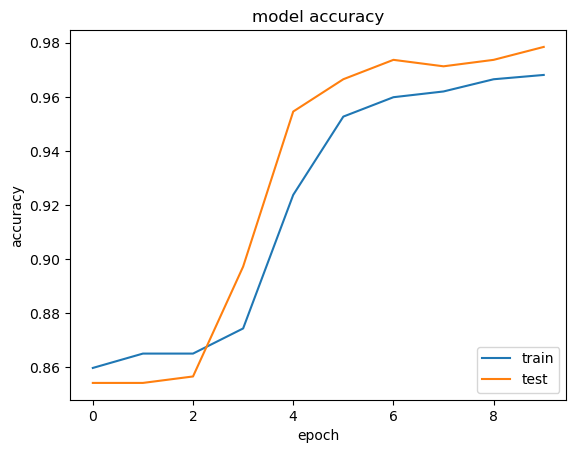

In [40]:
# visualise training history
plt.plot(m_history_lstm.history['acc'])
plt.plot(model_lstm.history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc="lower right")
plt.show()

### Exercise 13

Let's now retrain the model with GRU architecture.

Define the architecture of your model again, show its summary, compile it and train it.

In [41]:
#Add your code here
model_gru = Sequential()
model_gru.add(Input(shape=(50, )))
model_gru.add(Embedding(input_dim=vocab_size, output_dim=embd_dim, embeddings_initializer=keras.initializers.Constant(embd_weights), trainable=False, mask_zero=True))
model_gru.add(GRU(50))
model_gru.add(Dense(1, activation='sigmoid'))
model_gru.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 50, 300)        │     1,500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 50)             │        52,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,552,851 (5.92 MB)

 Trainable params: 52,851 (206.45 KB)

 Non-trainable params: 1,500,000 (5.72 MB)

In [42]:
#Add your code here

model_gru.compile(optimizer=Adam(0.00005), loss='binary_crossentropy', metrics=['acc'])

In [43]:
#Add your code here
m_history_gru = model_gru.fit(X_train, y_train, batch_size=32, epochs=10, validation_split=0.1)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - acc: 0.7671 - loss: 0.6095 - val_acc: 0.8541 - val_loss: 0.5044
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.8649 - loss: 0.4351 - val_acc: 0.8541 - val_loss: 0.3770
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - acc: 0.8649 - loss: 0.3489 - val_acc: 0.8541 - val_loss: 0.3287
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - acc: 0.8649 - loss: 0.3149 - val_acc: 0.8589 - val_loss: 0.2997
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - acc: 0.8673 - loss: 0.2885 - val_acc: 0.8684 - val_loss: 0.2711
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.8774 - loss: 0.2618 - val_acc: 0.8828 - val_loss: 0.2399
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.8968 - loss: 0.2334 - val_acc: 0.9091 - val_loss: 0.2073
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - acc: 0.9205 - loss: 0.2050 - val_acc: 0.9330 - val_loss: 0.1756
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/

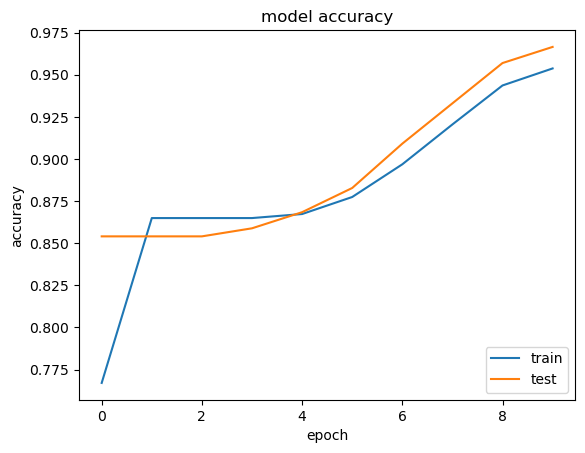

In [44]:
# visualise training history
plt.plot(m_history_gru.history['acc'])
plt.plot(model_gru.history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc="lower right")
plt.show()

## Regular Assignment
### Exercise 14

By now, hopefully the many-to-one RNN type makes sense. Let's now try a diffrent type, many-to-many.

We wish to build our own POS tagger. Recall how POS tags help us understand a first layer of the syntactic structure of a given sentence. 

There are various ways with which you can build a POS tagger. A rule-based one, a probabilistic one, using Hidden Markov Models (HMMs). There's also an option to build a statistical model to learn a POS tagger. 

We'll try the statistical approach. The training data is abundant, available through NLTK even.

We'll first acquire the TreeBank dataset.

In [45]:
#You might need to download the dataset first
nltk.download('treebank')

[nltk_data] Downloading package treebank to
[nltk_data]     /Users/cleojj002/nltk_data...
[nltk_data]   Package treebank is already up-to-date!


True

In [46]:
corpus = treebank.tagged_sents(tagset='universal')


Notice that each entry in the dataset is a tuple (word, pos_tag). We want our training **X** to have the words of the sentence, and **Y** to have the equivalent POS tags.

In [47]:
i=25
print(type(corpus[i]))
print(corpus[i])

<class 'list'>
[('By', 'ADP'), ('1997', 'NUM'), (',', '.'), ('almost', 'ADV'), ('all', 'DET'), ('remaining', 'VERB'), ('uses', 'NOUN'), ('of', 'ADP'), ('cancer-causing', 'ADJ'), ('asbestos', 'NOUN'), ('will', 'VERB'), ('be', 'VERB'), ('outlawed', 'VERB'), ('*-6', 'X'), ('.', '.')]


a. Create your frame X which has all the sentences, and a frame Y with all the POS tags.

In [48]:
#Add your code here
X = []
Y = []
for idx in range(len(corpus)):
    cur_sentence = []
    cur_pos = []
    for word_pair in corpus[idx]:
        cur_sentence.append(word_pair[0])
        cur_pos.append(word_pair[1])
    X.append(cur_sentence)
    Y.append(cur_pos)


In [49]:
i=0
print(X[i])
print(Y[i])

['Pierre', 'Vinken', ',', '61', 'years', 'old', ',', 'will', 'join', 'the', 'board', 'as', 'a', 'nonexecutive', 'director', 'Nov.', '29', '.']
['NOUN', 'NOUN', '.', 'NUM', 'NOUN', 'ADJ', '.', 'VERB', 'VERB', 'DET', 'NOUN', 'ADP', 'DET', 'ADJ', 'NOUN', 'NOUN', 'NUM', '.']


### Exercise 15

Check that you have the same number of entries in X and Y.

Check also that every entry in X, has the same number of elements as in its equivalent of Y.

If a sentence in X has 5 tokens, we need to have 5 POS tags in Y.

In [50]:
#Add your code here
print("Length is SAME: ", len(X) == len(Y))
print("Total sentences: ", len(X))
def check_alignment(X, Y):
    for idx in range(len(X)):
        if len(X[idx]) != len(Y[idx]):
            return False
    return True

print("Check equal tokens: ", check_alignment(X, Y))

Length is SAME:  True
Total sentences:  3914
Check equal tokens:  True


3914 sentences is enough training data for our model.

### Exercise 16

a. Let's now move on to convert X and Y both to integers, using Keras's tokenizer.

In [51]:
#Add your code here
x_tokenizer = Tokenizer(filters='', lower=False, oov_token='<UNK>')
x_tokenizer.fit_on_texts(X)
X_encoded = x_tokenizer.texts_to_sequences(X)

y_tokenizer = Tokenizer(filters='', lower=False)
y_tokenizer.fit_on_texts(Y)
Y_encoded = y_tokenizer.texts_to_sequences(Y)


a. Let's print the size of the vocab, also the number of different POS tags we have.

We need to know how many different POS tags we have, because that should be our number of classes.

In [52]:
#Add your code here
x_vocab_size = len(x_tokenizer.word_index) + 1   # +1 for padding (index 0)
n_classes = len(y_tokenizer.word_index) + 1      

print("Size of vocab in X: ", x_vocab_size)                       
print("Number of different POS tags: ", len(y_tokenizer.word_index))  


Size of vocab in X:  12410
Number of different POS tags:  12


### Exercise 17

Let's again pad our sentences and our tags. We, again, need to decide on our max length, a decision that is crucial as this matches the number of time steps for our RNN architecture

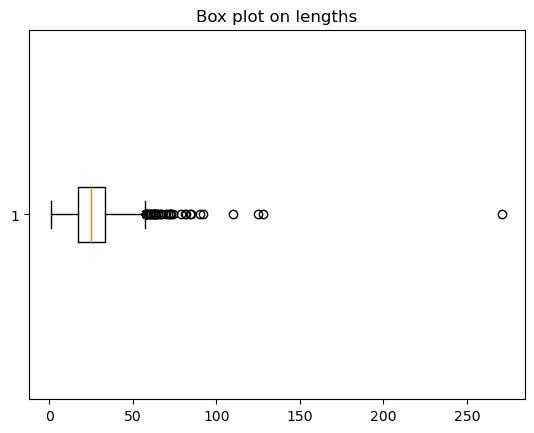

In [53]:
#Add your code here
sentences_length = [len(sentence) for sentence in X]

plt.boxplot(sentences_length, vert=False)
plt.title("Box plot on lengths")
plt.show()


In [54]:
chosen_max_len = 60
X_padded = pad_sequences(X_encoded, maxlen=chosen_max_len, truncating="post", padding="post")
Y_padded = pad_sequences(Y_encoded, maxlen=chosen_max_len, truncating="post", padding="post")

In [55]:
i=0
print(X_padded[i])
print(Y_padded[i])


[5947 3961    2 2091   89  444    2   45 2503    3  351   31    7 2092
  323  445 2093    4    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0]
[1 1 3 8 1 7 3 2 2 5 1 4 5 7 1 1 8 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### Exercise 18

Try a first version of your RNN models without using any pretrained embeddings.


a. Let's one-hot encode Y

In [56]:
#Add your code here
Y = to_categorical(Y_padded, num_classes=n_classes)
print(Y.shape)

(3914, 60, 13)


b. We create a train and test set.

In [57]:
# split entire data into training and testing sets
TEST_SIZE = 0.20
X_train, X_test, y_train, y_test = train_test_split(X_padded, Y, test_size=TEST_SIZE, random_state=100)

c. Define your RNN model, using a simple RNN. Compile it and fit it to the data.

Do not forget to wrap your Dense output layer with the TimeDistributed wrapper. We're doing a multiclassification at each time step.

In [58]:
#Add your code here
model = Sequential()
model.add(Input(shape=(chosen_max_len, )))
model.add(Embedding(input_dim=x_vocab_size, output_dim=32, mask_zero=True))
model.add(SimpleRNN(64, return_sequences=True))
model.add(TimeDistributed(Dense(n_classes, activation='softmax')))
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 60, 32)         │       397,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 60, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 60, 13)         │           845 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 404,173 (1.54 MB)

 Trainable params: 404,173 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:
#Add your code here
model.compile(optimizer=Adam(5e-4), loss="categorical_crossentropy",metrics=['acc'])

In [60]:
#Add your code here
m_history = model.fit(X_train, y_train, validation_split=0.1, batch_size=32, epochs=10)

Epoch 1/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - acc: 0.3156 - loss: 2.1891 - val_acc: 0.4445 - val_loss: 1.8758
Epoch 2/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.5555 - loss: 1.5648 - val_acc: 0.6859 - val_loss: 1.2504
Epoch 3/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.7491 - loss: 1.0095 - val_acc: 0.7999 - val_loss: 0.8194
Epoch 4/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - acc: 0.8359 - loss: 0.6599 - val_acc: 0.8523 - val_loss: 0.5784
Epoch 5/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.8896 - loss: 0.4491 - val_acc: 0.8916 - val_loss: 0.4304
Epoch 6/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.9303 - loss: 0.3136 - val_acc: 0.9147 - val_loss: 0.3353
Epoch 7/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.9554 - loss: 0.2246 - val_acc: 0.9312 - val_loss: 0.2758
Epoch 8/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.9683 - loss: 0.1668 - val_acc: 0.9378 - val_loss: 0.2378
Epoch 9/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.9760

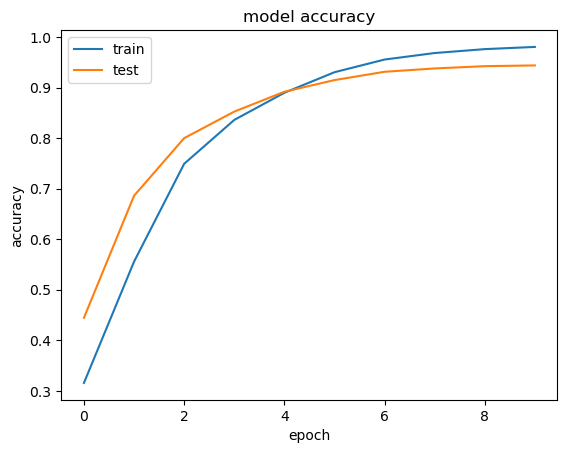

In [61]:
plt.plot(m_history.history['acc'], label='train')
plt.plot(model.history.history['val_acc'], label='test')
plt.title("model accuracy") 
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

### Exercise 19
Retrain the model with an LSTM. 
This should work faster, and yield better results.
Define, compile and fit your model.

In [62]:
#Add your code here
model_lstm = Sequential()
model_lstm.add(Input(shape=(chosen_max_len, )))
model_lstm.add(Embedding(input_dim=x_vocab_size, output_dim=32, mask_zero=True))
model_lstm.add(LSTM(60, return_sequences=True))
model_lstm.add(TimeDistributed(Dense(n_classes, activation='softmax')))

model_lstm.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 60, 32)         │       397,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 60, 60)         │        22,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 60, 13)         │           793 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,233 (1.60 MB)

 Trainable params: 420,233 (1.60 MB)

 Non-trainable params: 0 (0.00 B)

In [63]:
#Add your code here
model_lstm.compile(optimizer=Adam(5e-4), loss="categorical_crossentropy", metrics=['acc'])

In [64]:
#Add your code here
m_history_lstm = model_lstm.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.1)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - acc: 0.2926 - loss: 2.3456 - val_acc: 0.3466 - val_loss: 2.1458
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - acc: 0.4184 - loss: 1.9040 - val_acc: 0.5570 - val_loss: 1.5793
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - acc: 0.6508 - loss: 1.2884 - val_acc: 0.7285 - val_loss: 1.0259
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - acc: 0.7628 - loss: 0.8583 - val_acc: 0.7995 - val_loss: 0.7270
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - acc: 0.8323 - loss: 0.6047 - val_acc: 0.8549 - val_loss: 0.5373
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - acc: 0.8914 - loss: 0.4270 - val_acc: 0.9019 - val_loss: 0.4067
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - acc: 0.9346 - loss: 0.3044 - val_acc: 0.9230 - val_loss: 0.3251
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - acc: 0.9561 - loss: 0.2269 - val_acc: 0.9343 - val_loss: 0.2764
Epoch 9/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - acc: 0.9670

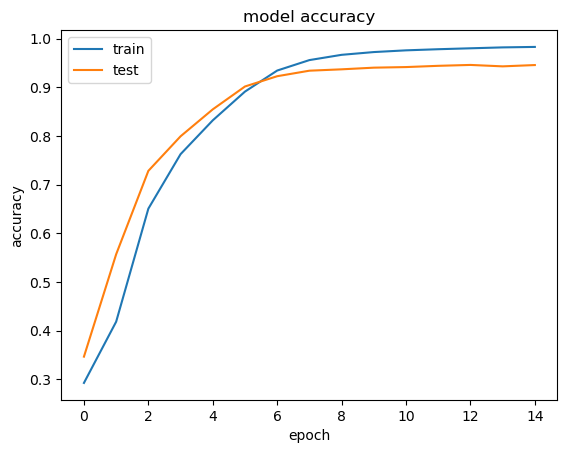

In [65]:
plt.plot(m_history_lstm.history['acc'], label="train")
plt.plot(model_lstm.history.history['val_acc'], label="test")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("model accuracy")
plt.legend()
plt.show()

### Exercise 20
Retrain the model with a GRU. 

In [66]:
#Add your code here
model_gru = Sequential()
model_gru.add(Input(shape=(chosen_max_len, )))
model_gru.add(Embedding(input_dim=x_vocab_size, output_dim=32, mask_zero=True))
model_gru.add(GRU(60, return_sequences=True))
model_gru.add(TimeDistributed(Dense(n_classes, activation='softmax')))
model_gru.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ (None, 60, 32)         │       397,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 60, 60)         │        16,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 60, 13)         │           793 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 414,833 (1.58 MB)

 Trainable params: 414,833 (1.58 MB)

 Non-trainable params: 0 (0.00 B)

In [67]:
model_gru.compile(optimizer=Adam(5e-4), loss="categorical_crossentropy", metrics=['acc'])

In [68]:
#Add your code here
m_history_gru = model_gru.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1)

Epoch 1/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - acc: 0.3337 - loss: 2.2386 - val_acc: 0.4598 - val_loss: 1.8030
Epoch 2/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - acc: 0.6126 - loss: 1.3986 - val_acc: 0.7139 - val_loss: 1.0284
Epoch 3/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - acc: 0.7661 - loss: 0.8113 - val_acc: 0.8201 - val_loss: 0.6489
Epoch 4/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - acc: 0.8673 - loss: 0.5121 - val_acc: 0.8909 - val_loss: 0.4525
Epoch 5/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - acc: 0.9210 - loss: 0.3439 - val_acc: 0.9193 - val_loss: 0.3438
Epoch 6/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - acc: 0.9466 - loss: 0.2445 - val_acc: 0.9314 - val_loss: 0.2811
Epoch 7/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - acc: 0.9637 - loss: 0.1830 - val_acc: 0.9389 - val_loss: 0.2436
Epoch 8/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - acc: 0.9717 - loss: 0.1436 - val_acc: 0.9414 - val_loss: 0.2203
Epoch 9/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - acc: 0.9763

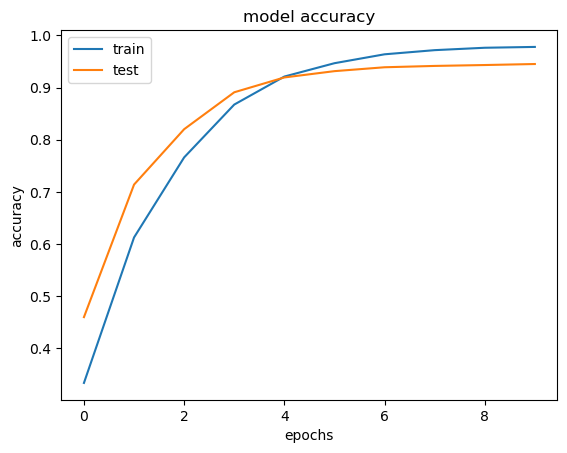

In [69]:
#Add your code here
plt.plot(m_history_gru.history['acc'], label='train')
plt.plot(model_gru.history.history['val_acc'], label='test')
plt.title("model accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.legend()
plt.show()

### Exercise 21
Save one of your models (the one with the best performance) as an h5 file. This is a straightforward operation, refer to [here](https://keras.io/api/models/model_saving_apis/).

You will use it on the **Advanced** part of the assignment to make inferences.

In [70]:
model_gru.save('model_gru.h5')

In [71]:
import json
with open("x_tokenizer.json", "w") as f:
    f.write(x_tokenizer.to_json())
with open("y_tokenizer.json", "w") as f:
    f.write(y_tokenizer.to_json())